<br>

# **3.0. Modeling - LogisticRegression**:

> 3.1. **Baseline Model: Dummy Classifier** <br>
> 3.2. **Training the Model - Fit Logistic Regression** <br>
> 3.3. **Predict & Evaluate** <br>
> 3.4. **Classification Report & Confusion Matrix** <br>
> 3.5. **Probability Calibration** <br>
> 3.6. **Kolmogorov-Smirnov (KS) Statistics** <br>
> 3.7. **Expected Cost-Function** <br>
> 3.8. **Credit Scorecard** <br>
> 3.9. **PCA 2D Visualization** <br>



In [1]:
# Libraries
import pandas as pd
import numpy as np

# Logging
import logging
import time

# Joblib
import joblib

# CPU Cores & System
import os
import sys

if os.getcwd().endswith('notebooks'):
    %cd ..

# Viz libraries
import seaborn as sns
import matplotlib as mpl
import matplotlib.pyplot as plt
%matplotlib inline

# Plotting options
%matplotlib inline
mpl.style.use('ggplot')
sns.set(style='whitegrid')

# Import warnings
import warnings
warnings.filterwarnings('ignore')

# Pandas set_option
pd.set_option('display.max_columns', None)
# Experiment tracking
import mlflow


/home/gontommuhammad/credit_risk_modeling


In [2]:
from src.utils import deserialize_data

# X set:
X_train_lr = deserialize_data('data/processed/logreg/X_train_lr.pkl')
X_valid_lr = deserialize_data('data/processed/logreg/X_valid_lr.pkl')
X_test_lr  = deserialize_data('data/processed/logreg/X_test_lr.pkl')

# y set:
y_train = deserialize_data('data/interim/y_train.pkl')
y_valid = deserialize_data('data/interim/y_valid.pkl')
y_test  = deserialize_data('data/interim/y_test.pkl')

Data successfully deserialized from data/processed/logreg/X_train_lr.pkl
Data successfully deserialized from data/processed/logreg/X_valid_lr.pkl
Data successfully deserialized from data/processed/logreg/X_test_lr.pkl
Data successfully deserialized from data/interim/y_train.pkl
Data successfully deserialized from data/interim/y_valid.pkl
Data successfully deserialized from data/interim/y_test.pkl


In [3]:
X_train_lr.info()

<class 'pandas.DataFrame'>
Index: 84764 entries, 118760 to 2427956
Data columns (total 12 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   annual_inc_woe          84764 non-null  float64
 1   credit_age_years_woe    84764 non-null  float64
 2   dti_woe                 84764 non-null  float64
 3   emp_length_ordinal_woe  84764 non-null  float64
 4   has_derogatory_woe      84764 non-null  float64
 5   home_ownership_woe      84764 non-null  float64
 6   inq_last_6mths_woe      84764 non-null  float64
 7   loan_to_income_woe      84764 non-null  float64
 8   open_acc_ratio_woe      84764 non-null  float64
 9   purpose_woe             84764 non-null  float64
 10  revol_util_woe          84764 non-null  float64
 11  term_woe                84764 non-null  float64
dtypes: float64(12)
memory usage: 8.4 MB


In [4]:
RANDOM_STATE = 42

<br>

---
### **Split Data: for Calibration Set:**

In [5]:
print(f"X_train shape: {X_train_lr.shape}, y_train shape: {y_train.shape}")

X_train shape: (84764, 12), y_train shape: (84764,)


In [6]:
TRAIN_CAL_SIZE = 10 / 90

from src.utils import split_train_test
X_train_lr, X_train_cal, y_train, y_train_cal = split_train_test(
    X_train_lr, 
    y_train,
    test_size=TRAIN_CAL_SIZE, 
    stratify=y_train,
    seed=RANDOM_STATE
)

In [7]:
# ── MLflow experiment tracking ──
mlflow.set_tracking_uri("sqlite:///mlflow.db")
mlflow.set_experiment("logistic-regression-scorecard")
mlflow_run = mlflow.start_run(run_name="logreg_woe_scorecard")
mlflow.log_params({
    "random_state": RANDOM_STATE,
    "train_cal_share": TRAIN_CAL_SIZE,
    "c_fn": 8_250_000.0,
    "c_fp": 2_700_000.0,
})
print(f"MLflow run started: {mlflow_run.info.run_id}")

MLflow run started: 017d4888259a477cbf782a95c5010ea5


In [8]:
print(f"X_train shape: {X_train_lr.shape}, y_train shape: {y_train.shape}")

X_train shape: (75345, 12), y_train shape: (75345,)


In [9]:
print(f"X_train cal shape: {X_train_cal.shape}, y_train cal shape: {y_train_cal.shape}")

X_train cal shape: (9419, 12), y_train cal shape: (9419,)


<br>

---
### **Import Metrics from Scikit Learn:**

In [10]:
from sklearn.metrics import (
    precision_score, recall_score, f1_score, roc_auc_score, roc_curve, auc, log_loss, 
    matthews_corrcoef, classification_report, confusion_matrix, balanced_accuracy_score, 
    average_precision_score, brier_score_loss, precision_recall_curve, accuracy_score
)

<br>

---
## **3.1. Baseline Model: Dummy Classifier**:

In [11]:
from sklearn.dummy import DummyClassifier
# Create an object
dummy_clf = DummyClassifier(
    strategy='most_frequent',
    random_state=RANDOM_STATE
)
# Perform a fit, for y_train data only
dummy_clf.fit(
    X=X_train_lr, 
    y=y_train
)

DummyClassifier(random_state=42, strategy='most_frequent')

In [12]:
# Predict
y_pred_dummy = dummy_clf.predict(X_train_lr)

In [13]:
# Confusion matrix
confusion_matrix(
    y_true=y_train,
    y_pred=y_pred_dummy
)
# [[tn, fp]]
# [[fn, tp]]

array([[63821,     0],
       [11524,     0]])

In [14]:
# Accuracy score
accuracy_score(
    y_true=y_train,
    y_pred=y_pred_dummy
)
# Same as the largest class proportion

0.847050235582985

**BASELINE PRIOR CLASS PROBABILITY**
- Find the probability of each class appearing
- Find the proportion of each class appearing in the training data
- Find the total odds of the class appearing based on the prior probability

In [15]:
print(f"y_train  :", y_train.value_counts(normalize=True))
print(f'y_valid  :', y_valid.value_counts(normalize=True))
print(f'y_test   :', y_test.value_counts(normalize=True))

y_train  : target
0    0.84705
1    0.15295
Name: proportion, dtype: float64
y_valid  : target
0    0.85202
1    0.14798
Name: proportion, dtype: float64
y_test   : target
0    0.860549
1    0.139451
Name: proportion, dtype: float64


In [16]:
# Create an object
dummy_clf = DummyClassifier(
    strategy='stratified',
    random_state=RANDOM_STATE
)
# Perform a fit, for y_train data only
dummy_clf.fit(
    X=X_train_lr,
    y=y_train
)

DummyClassifier(random_state=42, strategy='stratified')

In [17]:
# Predict
y_pred_dummy = dummy_clf.predict(X_train_lr)

In [18]:
# Display confusion matrix
confusion_matrix(
    y_true=y_train,
    y_pred=y_pred_dummy
)
# [[tn, fp]]
# [[fn, tp]]

array([[54109,  9712],
       [ 9781,  1743]])

In [19]:
# Check accuracy
accuracy_score(
    y_true=y_train,
    y_pred=y_pred_dummy
)

0.7412834295573695

In [20]:
# Balanced accuracy
balanced_accuracy_score(
    y_true=y_train,
    y_pred=y_pred_dummy
)

np.float64(0.49953697497319016)

In [21]:
# Calculate performance metrics
precision = precision_score(
    y_train, 
    y_pred_dummy, 
    pos_label=1, 
    zero_division=0
)
recall = recall_score(
    y_train, 
    y_pred_dummy, 
    pos_label=1
)
f1 = f1_score(
    y_train, 
    y_pred_dummy, 
    average='weighted'
)
roc_auc = roc_auc_score(
    y_train, 
    dummy_clf.predict_proba(X_train_lr)[:, 1]
)
# Print the results
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1 Score  : {f1:.4f}")
print(f"ROC AUC   : {roc_auc:.4f}")

Precision : 0.1522
Recall    : 0.1512
F1 Score  : 0.7410
ROC AUC   : 0.4995


In [22]:
# Buat weight class
n_samples = len(y_train)
n_classes = len(y_train.value_counts())
n_samples_j = y_train.value_counts()

class_weight = n_samples / (n_classes * n_samples_j)
class_weight

# We give more weight to class 1

target
0    0.590284
1    3.269047
Name: count, dtype: float64

<br>

---
## **3.3. Training the Model - Fit Logistic Regression:**

In [23]:
# Import library
from sklearn.linear_model import LogisticRegression

In [24]:
# logreg = LogisticRegression(
#     C=1.1386384045816267,
#     class_weight=None,
#     l1_ratio=0.004532623967562711,
#     max_iter=2000,
#     penalty='elasticnet',
#     random_state=RANDOM_STATE,
#     solver='saga'
# )

logreg = LogisticRegression(
    C=0.496024651248498,
    class_weight=None,
    l1_ratio=0.0,
    max_iter=2000,
    penalty='elasticnet',
    random_state=RANDOM_STATE,
    solver='saga'
)
logreg.fit(X_train_lr, y_train)

# Log model hyperparameters
mlflow.log_params({
    k: v for k, v in logreg.get_params().items()
    if isinstance(v, (int, float, str, bool, type(None)))
})


---
## **3.4. Predict & Evaluate**

<br>

### **F1 Threshold**: 

F1 Threshold: 0.1376


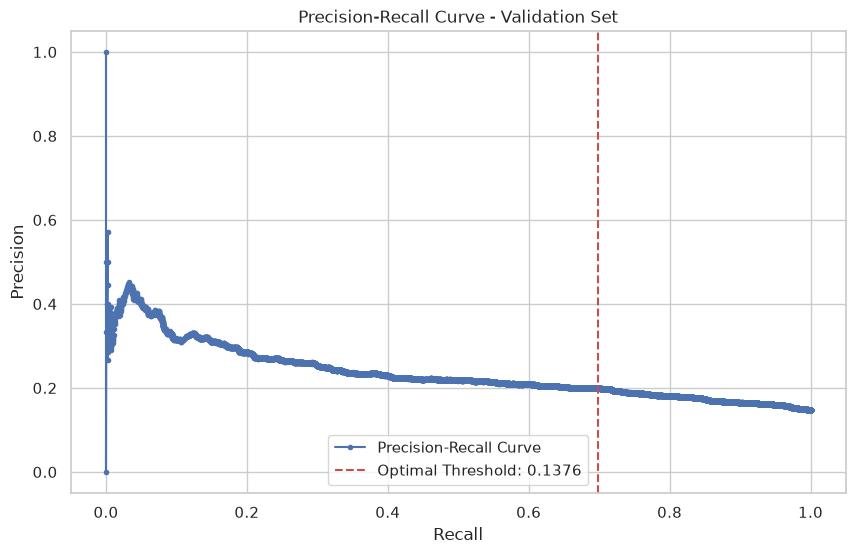

In [25]:
# PR curve only in Validation Set
precisions, recalls, thresholds = precision_recall_curve(
    y_valid,
    logreg.predict_proba(X_valid_lr)[:, 1]
)

# Align arrays
precisions_t = precisions[:-1]
recalls_t = recalls[:-1]

# F1 per threshold
f1_scores = np.where(
    (precisions_t + recalls_t) > 0,
    2 * precisions_t * recalls_t / (precisions_t + recalls_t),
    0
)
optimal_idx = np.argmax(f1_scores)
f1_threshold = thresholds[optimal_idx]

print(f"F1 Threshold: {f1_threshold:.4f}")

# Plot Precision-Recall Curve
plt.figure(figsize=(10, 6))
plt.plot(recalls, precisions, marker='.', label=f"Precision-Recall Curve")
plt.axvline(recalls[optimal_idx], color='r', linestyle='--', label=f"Optimal Threshold: {f1_threshold:.4f}")
plt.xlabel(f"Recall")
plt.ylabel(f"Precision")
plt.title(f"Precision-Recall Curve - Validation Set")
plt.legend()
plt.show()

<br>

### **Cost-based Threshold**:

In [26]:
# Economic parameters:
c_fn = 8_250_000.0   # Cost False Negative: EAD * LGD = 15m * 0.55
c_fp = 2_700_000.0   # Cost False Positive: EAD * spread * duration = 15m * 0.09 * 2

"""
The threshold that minimizes: 
    
E[C(tau)] = c_fn * P(y=1) * FNR(tau) + c_fp * P(y=0) * FPR(tau).

The only criterion that is genuinely independent of F1 and Youden's 
because it is based on the economic objective function, 
not statistical discrimination or precision-recall.
"""

from src.thresholding import find_best_cost_threshold

# ── RUN ──
optimal_cost_threshold, optimal_cost = find_best_cost_threshold(
    y_true=y_valid, 
    y_proba=logreg.predict_proba(X_valid_lr)[:, 1],
    c_fn=c_fn, c_fp=c_fp
)
print(f"Optimal Cost-based Threshold: {optimal_cost_threshold:.4f}; Optimal Cost: {optimal_cost:.4f}")

Optimal Cost-based Threshold: 0.2993; Optimal Cost: 1166959.2299


<br>

**Function to Evaluate Modelt**:

In [27]:
def evaluate_model(
    model, 
    X, y, 
    model_name, 
    split_set, 
    threshold=None):
    """
    Evaluate binary classification model.
    
    Parameters
    ----------
    model : fitted estimator
        Trained model with predict() and predict_proba().
    
    X : array-like
        Features.
    
    y : array-like
        True labels.
    
    threshold : float
        Must be taken from Validation Set.
     
    model_name : object
    
    split_set : str
        Train / Validation / Test.
    
    Returns
    -------
    Metrics table          : pd.DataFrame
    Confusion Matrix       : pd.DataFrame
    Classification Report  : String
    y prediction           : array-like
    y probability          : array-like
    """
    
    if threshold is None:
        y_pred = model.predict(X)
    else:
        y_pred = (
            model.predict_proba(X)[:, 1] >= threshold
        ).astype(int)
    
    y_proba = model.predict_proba(X)[:, 1]
    
    from src.ks_statistic_evaluation import compute_ks_statistic
    ks_result = compute_ks_statistic(y, y_proba)
    
    from src.metrics import threshold_classification_metrics
    thres_metrics = threshold_classification_metrics(y, y_proba, threshold)
    
    metrics_df = pd.DataFrame([{
        'Model': model_name,
        'Split': split_set,
        'ROC-AUC': round(roc_auc_score(y, y_proba), 6),
        'PR-AUC': round(average_precision_score(y, y_proba), 6),
        'LogLoss': round(log_loss(y, y_proba), 6),
        'Brier Score': round(brier_score_loss(y, y_proba), 6),
        'Gini': round(2 * roc_auc_score(y, y_proba) - 1, 6),
        'KS_Statistic': round(ks_result['ks_statistic_roc'], 6),
        **thres_metrics
    }])
    
    return metrics_df, y_pred, y_proba

In [28]:
train_metrics, y_pred_train, y_proba_train = evaluate_model(
    model=logreg, 
    X=X_train_lr, y=y_train, 
    model_name='Logistic Regression', 
    split_set='Training',
    threshold=optimal_cost_threshold
)

valid_metrics, y_pred_valid, y_proba_valid = evaluate_model(
    model=logreg, 
    X=X_valid_lr, y=y_valid, 
    model_name='Logistic Regression', 
    split_set='Validation',
    threshold=optimal_cost_threshold
)

test_metrics, y_pred_test, y_proba_test = evaluate_model(
    model=logreg, 
    X=X_test_lr, y=y_test, 
    model_name='Logistic Regression', 
    split_set='Test',
    threshold=optimal_cost_threshold
)

results = pd.concat([
    train_metrics,
    valid_metrics, 
    test_metrics

], ignore_index=True).set_index(['Model', 'Split'])

display(results)

# Log evaluation metrics to MLflow
for (model_name, split_name), row in results.iterrows():
    mlflow.log_metrics({
        f"{split_name.lower()}__roc_auc":      float(row["ROC-AUC"]),
        f"{split_name.lower()}__pr_auc":       float(row["PR-AUC"]),
        f"{split_name.lower()}__log_loss":     float(row["LogLoss"]),
        f"{split_name.lower()}__brier":        float(row["Brier Score"]),
        f"{split_name.lower()}__ks":           float(row["KS_Statistic"]),
        f"{split_name.lower()}__recall_bad":   float(row["Recall_Bad"]),
    }, step=0)

ROC-AUC    PR-AUC   LogLoss  Brier Score  \
Model               Split                                                   
Logistic Regression Training    0.670946  0.262976  0.403565     0.123173   
                    Validation  0.639363  0.235799  0.404389     0.122267   
                    Test        0.638646  0.210678  0.391910     0.117545   

                                    Gini  KS_Statistic  Balanced_Accuracy  \
Model               Split                                                   
Logistic Regression Training    0.341893      0.245765           0.545099   
                    Validation  0.278726      0.213047           0.545232   
                    Test        0.277292      0.212486           0.530344   

                                     MCC  Precision_Bad  Recall_Bad    F1_Bad  \
Model               Split                                                       
Logistic Regression Training    0.134095       0.339843    0.138927  0.197228   
                    Validation  0.129579       0.321377    0.142857  0.197792   
                    Test        0.086169       0.254024    0.115789  0.159071   

                                Specificity       NPV       FPR       FNR  \
Model               Split                                                   
Logistic Regression Training       0.951270  0.859515  0.048730  0.861073   
                    Validation     0.947607  0.864229  0.052393  0.857143   
                    Test           0.944898  0.868326  0.055102  0.884211   

                                Predicted_Bad_Rate     TN    FP    FN    TP  
Model               Split                                                    
Logistic Regression Training              0.062526  60711  3110  9923  1601  
                    Validation            0.065780   8555   473  1344   224  
                    Test                  0.063565  18280  1066  2772   363

<br>

---
## **3.5. Classification Report & Confusion Matrix**: <br> 

**LogReg - Training Set**:

In [29]:
from src.metrics import print_report_and_cm
print_report_and_cm(
    y_train, y_pred_train,
    f"Classification Report & Confusion Matrix | {f'Training Set'}"
)


Classification Report & Confusion Matrix | Training Set
              precision    recall  f1-score   support

    GOOD (0)       0.86      0.95      0.90     63821
     BAD (1)       0.34      0.14      0.20     11524

    accuracy                           0.83     75345
   macro avg       0.60      0.55      0.55     75345
weighted avg       0.78      0.83      0.80     75345



,Pred GOOD (0),Pred BAD (1)
Actual GOOD (0),60711,3110
Actual BAD (1),9923,1601


<br>

**LogReg - Validation Set**:

In [30]:
print_report_and_cm(
    y_valid, y_pred_valid,
    f"Classification Report & Confusion Matrix | {f'Valdation Set'}"
)


Classification Report & Confusion Matrix | Valdation Set
              precision    recall  f1-score   support

    GOOD (0)       0.86      0.95      0.90      9028
     BAD (1)       0.32      0.14      0.20      1568

    accuracy                           0.83     10596
   macro avg       0.59      0.55      0.55     10596
weighted avg       0.78      0.83      0.80     10596



,Pred GOOD (0),Pred BAD (1)
Actual GOOD (0),8555,473
Actual BAD (1),1344,224


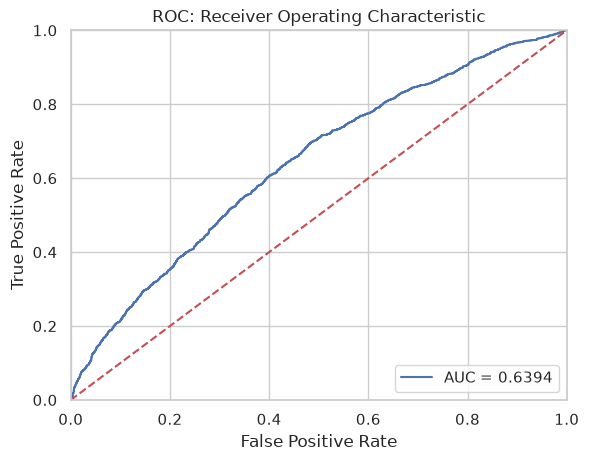

In [31]:
# ROC Curve
fpr_lr, tpr_lr, threshold_lr = roc_curve(
    y_valid,
    y_proba_valid
)
roc_auc_lr = auc(
    fpr_lr, 
    tpr_lr
)
plt.title(f"ROC: Receiver Operating Characteristic")
plt.plot(fpr_lr, tpr_lr, 'b', label = 'AUC = %0.4f' % roc_auc_lr)
plt.legend(loc = 'lower right')
plt.plot([0, 1], [0, 1],'r--')
plt.xlim([0, 1])
plt.ylim([0, 1])
plt.ylabel(f"True Positive Rate")
plt.xlabel(f"False Positive Rate")
plt.show()

In [32]:
df_actual_predicted = pd.concat([pd.DataFrame(np.array(y_valid), columns=['y_actual']), pd.DataFrame(y_proba_valid, columns=['y_pred_proba'])], axis=1)
df_actual_predicted.index = y_valid.index

df_actual_predicted = df_actual_predicted.sort_values('y_pred_proba')
df_actual_predicted = df_actual_predicted.reset_index()

df_actual_predicted['Cumulative N Population'] = df_actual_predicted.index + 1
df_actual_predicted['Cumulative N Bad'] = df_actual_predicted['y_actual'].cumsum()
df_actual_predicted['Cumulative N Good'] = df_actual_predicted['Cumulative N Population'] - df_actual_predicted['Cumulative N Bad']
df_actual_predicted['Cumulative Perc Population'] = df_actual_predicted['Cumulative N Population'] / df_actual_predicted.shape[0]
df_actual_predicted['Cumulative Perc Bad'] = df_actual_predicted['Cumulative N Bad'] / df_actual_predicted['y_actual'].sum()
df_actual_predicted['Cumulative Perc Good'] = df_actual_predicted['Cumulative N Good'] / (df_actual_predicted.shape[0] - df_actual_predicted['y_actual'].sum())

In [33]:
df_actual_predicted.head()

,member_id,y_actual,y_pred_proba,Cumulative N Population,Cumulative N Bad,Cumulative N Good,Cumulative Perc Population,Cumulative Perc Bad,Cumulative Perc Good
0,2126764,0,0.023076,1,0,1,0.000094,0.0,0.000111
1,2036840,0,0.024347,2,0,2,0.000189,0.0,0.000222
2,2126776,0,0.025128,3,0,3,0.000283,0.0,0.000332
3,2639080,0,0.025220,4,0,4,0.000378,0.0,0.000443
4,3026800,0,0.025777,5,0,5,0.000472,0.0,0.000554


<br>

**LogReg - Test Set**:

In [34]:
print_report_and_cm(
    y_test, y_pred_test,
    f"Classification Report & Confusion Matrix | {f'Test Set'}"
)


Classification Report & Confusion Matrix | Test Set
              precision    recall  f1-score   support

    GOOD (0)       0.87      0.94      0.90     19346
     BAD (1)       0.25      0.12      0.16      3135

    accuracy                           0.83     22481
   macro avg       0.56      0.53      0.53     22481
weighted avg       0.78      0.83      0.80     22481



,Pred GOOD (0),Pred BAD (1)
Actual GOOD (0),18280,1066
Actual BAD (1),2772,363


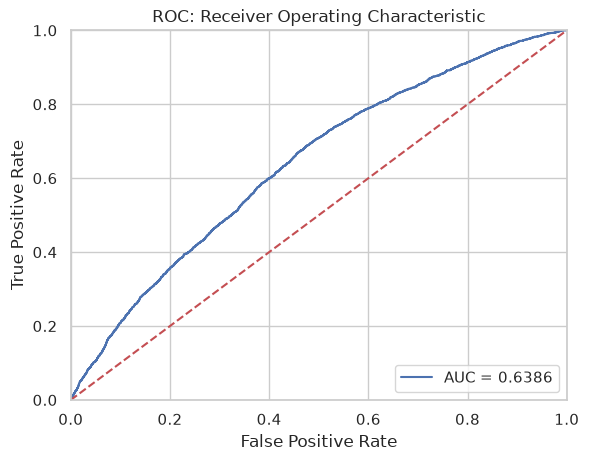

In [35]:
# ROC Curve
fpr_lr, tpr_lr, threshold_lr = roc_curve(
    y_test, 
    y_proba_test
)
roc_auc_lr = auc(
    fpr_lr, 
    tpr_lr
)
plt.title(f"ROC: Receiver Operating Characteristic")
plt.plot(fpr_lr, tpr_lr, 'b', label = 'AUC = %0.4f' % roc_auc_lr)
plt.legend(loc = 'lower right')
plt.plot([0, 1], [0, 1],'r--')
plt.xlim([0, 1])
plt.ylim([0, 1])
plt.ylabel(f"True Positive Rate")
plt.xlabel(f"False Positive Rate")
plt.show()

<br>

---
## **3.6. Probability Calibration:**

In [36]:
from src.calibration import CALIBRATION_STRATEGIES, run_probability_pipeline
from src.evaluation import extract_positive_proba

from src.calibration_selection import (
    evaluate_calibration_strategies,
    reliability_table,
    brier_skill_score
)

data_splits_logreg = {
    "train_cal": X_train_cal,   
    "valid":     X_valid_lr,   
    "test":      X_test_lr,
}

proba_store_lr = run_probability_pipeline(
    fitted_models={"logreg_scorecard": logreg},
    data_splits=data_splits_logreg,
    y_train_cal=y_train_cal,   
)

result = evaluate_calibration_strategies(
    proba_store_lr,
    y_by_split={"train_cal": y_train_cal, "valid": y_valid, "test": y_test},
    base_model_names=["logreg_scorecard"],
    decision_split="valid"  # select on validation, never on OOT test,
)

display(result.winners)   # strategi mana yang menang + Brier/LogLoss-nya di OOT
display(result.table)     # breakdown lengkap semua strategi x semua split, untuk laporan
display(reliability_table(y_test, proba_store_lr["logreg_scorecard_cal_sigmoid"]["test"]))  # kurva kalibrasi

,model,winning_strategy,brier_valid,logloss_valid
0,logreg_scorecard,raw,0.122267,0.404389


,model,strategy,split,brier,logloss
0,logreg_scorecard,raw,train_cal,0.122910,0.403149
1,logreg_scorecard,raw,valid,0.122267,0.404389
2,logreg_scorecard,raw,test,0.117545,0.391910
3,logreg_scorecard,sigmoid,train_cal,0.123306,0.404852
4,logreg_scorecard,sigmoid,valid,0.122745,0.405515
5,logreg_scorecard,sigmoid,test,0.118301,0.393904
6,logreg_scorecard,isotonic,train_cal,0.122254,0.400660
7,logreg_scorecard,isotonic,valid,0.122268,0.404510
8,logreg_scorecard,isotonic,test,0.117895,0.392784


,decile,count,mean_predicted,observed_rate
0,"(0.0621, 0.0878]",2249,0.080050,0.051578
1,"(0.0878, 0.0985]",2248,0.093339,0.081406
2,"(0.0985, 0.108]",2248,0.103329,0.091192
3,"(0.108, 0.119]",2248,0.113609,0.096085
4,"(0.119, 0.132]",2248,0.125122,0.124555
5,"(0.132, 0.147]",2248,0.139137,0.156584
6,"(0.147, 0.168]",2248,0.157120,0.171708
7,"(0.168, 0.201]",2248,0.182989,0.166370
8,"(0.201, 0.26]",2248,0.226823,0.198843
9,"(0.26, 0.79]",2248,0.355305,0.256228


In [37]:
pd.DataFrame([{**brier_skill_score(y_train_cal, logreg.predict_proba(X_train_cal)[:, 1])}])

,base_rate,brier_model,brier_trivial,skill_score
0,0.152989,0.12291,0.129583,0.051494


In [38]:
pd.DataFrame([{**brier_skill_score(y_valid, y_proba_valid)}])

,base_rate,brier_model,brier_trivial,skill_score
0,0.14798,0.122267,0.126082,0.030259


In [39]:
pd.DataFrame([{**brier_skill_score(y_test, y_proba_test)}])

,base_rate,brier_model,brier_trivial,skill_score
0,0.139451,0.117545,0.120004,0.020498


In [40]:
print("Train bad rate :", y_train.mean().round(6))
print("Cal   bad rate :", y_train_cal.mean().round(6))
print("Valid bad rate :", y_valid.mean().round(6))
print("Test  bad rate :", y_test.mean().round(6))

Train bad rate : 0.15295
Cal   bad rate : 0.152989
Valid bad rate : 0.14798
Test  bad rate : 0.139451


<br>

---
## **3.7. Kolmogorov-Smirnov (KS) Statistics**:

=== KS STATISTICS (WINNER MODEL: FINAL THRESHOLD ALIGNMENT) ===


,Dataset,KS Statistic,KS (%),KS Threshold,Interpretasi
0,Training (train_fit),0.2458,24.58,0.1537,adequate
1,Validation,0.2130,21.30,0.1376,adequate
2,Test,0.2125,21.25,0.1418,adequate


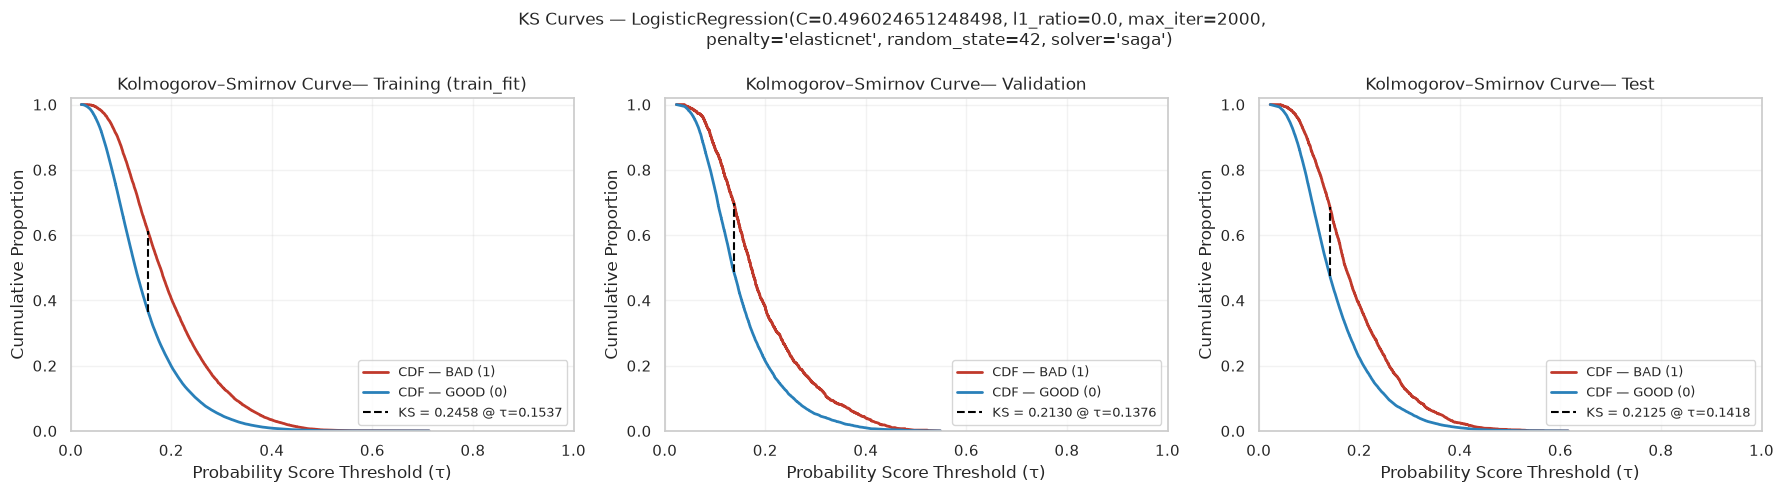

In [41]:
"""
Implementation of Kolmogorov-Smirnov (KS) Statistics as a Complementary Diagnostic
for the Evaluation of Binary Credit Risk Classification Models.

Theoretical context:
    KS = max_tau | F_BAD(tau) - F_GOOD(tau) |
       = max_tau | TPR(tau) - FPR(tau) |

Mathematically KS is identical to the maximum value of the Youden index (KS = max J),
but is reported as a single scalar that summarizes the overall separation capacity of the model,
accompanied by a visualization of two cumulative CDF curves of the prediction scores for each class (GOOD vs BAD).

Industry interpretation convention (Siddiqi, 2017, Credit Risk Scorecards):
    KS < 20%   : Weak discrimination
    20% - 40%  : Adequate discrimination
    > 40%      : Strong discrimination
"""

if __name__ == "__main__":
    
    datasets = {
        'Training (train_fit)' : (y_train, y_proba_train),
        'Validation'           : (y_valid, y_proba_valid),
        'Test'                 : (y_test,  y_proba_test),
    }
    print(f"=== KS STATISTICS (WINNER MODEL: FINAL THRESHOLD ALIGNMENT) ===")
    from src.ks_statistic_evaluation import ks_report_table, plot_ks_curve
    ks_table = ks_report_table(datasets)
    display(ks_table)
    
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    for ax, (name, (y_t, p)) in zip(axes, datasets.items()):
        plot_ks_curve(y_t, p, dataset_name=name, ax=ax)
    plt.suptitle(f"KS Curves — {logreg}", fontsize=12)
    plt.tight_layout()
    plt.savefig("reports/figures/ks_curves_all_partitions_LR.png", dpi=150)
    plt.show()
    pass

<br>

---
## **3.8. Expected Cost Function**:

===== Estimasi Komponen Biaya =====
C_FN (kerugian default) : 8250000.0000
C_FP (opportunity cost) : 2700000.0000
Rasio C_FN/C_FP         : 3.0556
Tau optimal-biaya       : 0.2993
Recall BAD di tau optimal-biaya : 0.1429

===== Perbandingan Ambang Threshold =====
Tau optimal-biaya : 0.2993
Tau Youden's J    : 0.1376
Tau F1 maksimal   : 0.1376
Rasio C_FN/C_FP   : 3.0600
Interpretasi: Dengan rasio C_FN/C_FP = 3.0556, ambang optimal-biaya berada di atas ambang Youden -- selisih 0.1617 pada skala probabilitas.


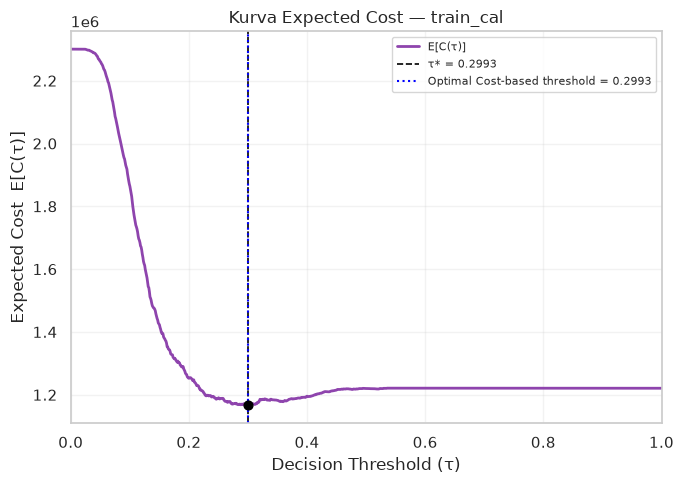

In [42]:
"""
Implementasi Fungsi Expected Cost untuk Penentuan Ambang Keputusan Optimal-Biaya
pada Model Klasifikasi Risiko Kredit Biner.

Kerangka teoretis (Elkan, 2001; BCBS, 2006 untuk estimasi komponen LGD/EAD):

    E[C(tau)] = C_FN * P(y=1) * P(yhat=0 | y=1, tau)
              + C_FP * P(y=0) * P(yhat=1 | y=0, tau)

    di mana:
        P(yhat=0 | y=1, tau) = 1 - Recall_BAD(tau)      [False Negative Rate]
        P(yhat=1 | y=0, tau) = FPR(tau)                  [False Positive Rate]

    C_FN (biaya false negative, memberi pinjaman pada peminjam yang gagal bayar)
        didekomposisi sebagai:  C_FN ≈ EAD * LGD

    C_FP (biaya false positive, menolak peminjam yang sesungguhnya baik)
        didekomposisi sebagai opportunity cost margin bunga marjinal:
        C_FP ≈ EAD * spread_bunga * durasi_pinjaman

    tau* = argmin_tau E[C(tau)]

Catatan epistemik penting:
    C_FN dan C_FP di sini adalah ESTIMASI PORTOFOLIO-LEVEL, bukan kepastian
    per-individu. Modul ini menyediakan dua mode: (a) biaya skalar tetap
    (rasio C_FN/C_FP konstan di seluruh observasi), dan (b) biaya per-observasi
    bila EAD bervariasi antar peminjam (mis. plafon pinjaman berbeda) --
    mode (b) lebih realistis untuk portofolio kredit konsumen heterogen.
"""

if __name__ == "__main__":
    # --- Scalar mode: portfolio mean estimate ---
    # Misal: EAD rata-rata Rp 15.000.000, LGD historis 55%,
    # For example: Average EAD Rp. 15,000,000, historical LGD 55%,
    # interest spread 9%/year, average loan duration 2 years.
    from src.expected_cost_threshold import (
    estimate_cost_components, expected_cost_curve_scalar, 
    compare_threshold_criteria, plot_expected_cost_curve)
    
    components = estimate_cost_components(
        ead=15_000_000,
        lgd=0.55,
        interest_spread=0.09,
        loan_duration_years=2.0,
    )
    def print_cost_report(components):
        print(f"===== Estimasi Komponen Biaya =====")
        print(f"C_FN (kerugian default) : {components['C_FN']:.4f}")
        print(f"C_FP (opportunity cost) : {components['C_FP']:.4f}")
        print(f"Rasio C_FN/C_FP         : {components['ratio_CFN_CFP']:.4f}")

    print_cost_report(components)
    # C_FN = 15jt * 0.55 = 8.25jt
    # C_FP = 15jt * 0.09 * 2 = 2.7jt
    # rasio C_FN/C_FP ≈ 3.06
    
    cost_result = expected_cost_curve_scalar(
        y_valid, y_proba_valid,
        c_fn=components['C_FN'], c_fp=components['C_FP']
    )
    print(f"Tau optimal-biaya       : {cost_result['optimal_threshold']:.4f}")
    print(f"Recall BAD di tau optimal-biaya : {cost_result['optimal_recall_bad']:.4f}\n")
    
    comparison = compare_threshold_criteria(
        y_valid, y_proba_valid, components['C_FN'], components['C_FP']
    )
    print(f"===== Perbandingan Ambang Threshold =====")
    print(f"Tau optimal-biaya : {comparison['tau_expected_cost']:.4f}")
    print(f"Tau Youden's J    : {comparison['tau_youden_j']:.4f}")
    print(f"Tau F1 maksimal   : {comparison['tau_f1_maximal']:.4f}")
    print(f"Rasio C_FN/C_FP   : {comparison['cost_ratio_CFN_CFP']:.4f}")
    print(f"Interpretation: {comparison['interpretation']}")
    
    ax_cost = plot_expected_cost_curve(cost_result, dataset_name='train_cal')

    ax_cost.axvline(
        optimal_cost_threshold,
        color='blue', linestyle=':', linewidth=1.5,
        label=f"Optimal Cost-based threshold = {optimal_cost_threshold:.4f}"
    )
    ax_cost.legend(fontsize=8)
    plt.tight_layout()
    plt.savefig("reports/figures/expected_cost_curve_valid_LR.png", dpi=150)
    plt.show()
    pass

<br>

---
## **3.9. Credit Scorecard**:

In [43]:
# Coefficient
logreg.coef_

array([[-0.89927   , -0.48733798, -0.10895864, -1.0826025 , -1.19459531,
        -0.51372671, -1.16928512, -0.55628951, -1.05647015, -0.83807591,
        -1.04975114, -0.89609795]])

In [44]:
# Intercept
logreg.intercept_

array([-1.71320329])

=== TOP 5 HIGH RISK INDICATORS (Lower Score) ===
Empty DataFrame
Columns: [Characteristics, Coefficient, Point]
Index: []

=== TOP 5 LOW RISK INDICATORS (Increasing Score) ===
       Characteristics  Coefficient  Point
    has_derogatory_woe    -1.194595     34
    inq_last_6mths_woe    -1.169285     34
emp_length_ordinal_woe    -1.082603     31
    open_acc_ratio_woe    -1.056470     30
        revol_util_woe    -1.049751     30


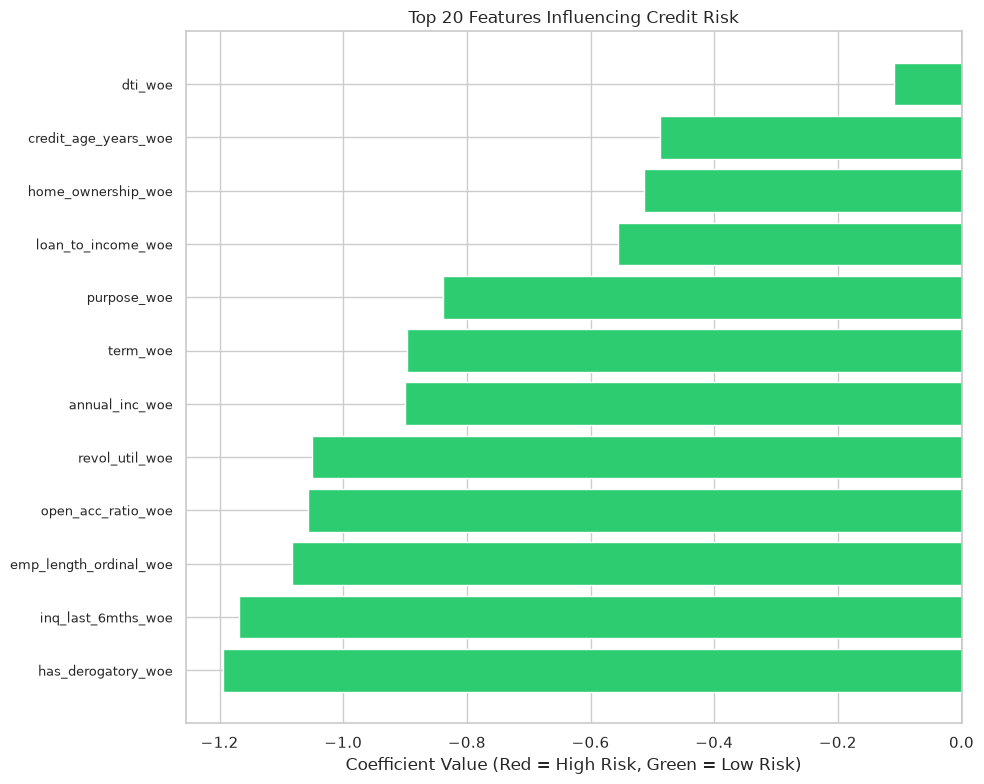

,Characteristics,Coefficient,Point
0,Base Score (Intercept),-1.713203,537
1,has_derogatory_woe,-1.194595,34
2,inq_last_6mths_woe,-1.169285,34
3,emp_length_ordinal_woe,-1.082603,31
4,open_acc_ratio_woe,-1.056470,30
5,revol_util_woe,-1.049751,30
6,annual_inc_woe,-0.899270,26
7,term_woe,-0.896098,26
8,purpose_woe,-0.838076,24
9,loan_to_income_woe,-0.556290,16



=== AUTOMATIC WRONG-SIGN COEFFICIENT DETECTION ===


,Feature,Coefficient,Expected Sign,Status
0,annual_inc_woe,-0.899270,Negative (< 0),OK
1,credit_age_years_woe,-0.487338,Negative (< 0),OK
2,dti_woe,-0.108959,Negative (< 0),OK
3,emp_length_ordinal_woe,-1.082603,Negative (< 0),OK
4,has_derogatory_woe,-1.194595,Negative (< 0),OK
5,home_ownership_woe,-0.513727,Negative (< 0),OK
6,inq_last_6mths_woe,-1.169285,Negative (< 0),OK
7,loan_to_income_woe,-0.556290,Negative (< 0),OK
8,open_acc_ratio_woe,-1.056470,Negative (< 0),OK
9,purpose_woe,-0.838076,Negative (< 0),OK



Suggested features to drop: []


In [45]:
def build_comprehensive_scorecard(model, feature_names, target_score=600, target_odds=50, pdo=20):
    """
    Functions for evaluating coefficients and building Credit Scorecards.
    """
    # =======================================================
    # PART 1: SCORECARD PARAMETERS CALCULATION
    # =======================================================
    # Scorecard calibration standard formula:
    factor = pdo / np.log(2)
    offset = target_score - (factor * np.log(target_odds))
    
    intercept = model.intercept_[0]
    coefs = model.coef_[0]
    
    # Since the model predicts BAD (default), a positive probability value indicates high risk.
    # To make a high scorecard score mean "Safe/Good," we assign a negative sign to the coefficient.
    base_score = offset - (intercept * factor)
    
    # =======================================================
    # PART 2: TABLE CREATION AND POINT CALCULATION
    # =======================================================
    # Combine features and coefficients into a DataFrame
    df_scorecard = pd.DataFrame({
        'Characteristics': feature_names,
        'Coefficient': coefs
    })
    
    # Count points and round to integer (banking standard)
    df_scorecard['Point'] = -(df_scorecard['Coefficient'] * factor)
    df_scorecard['Point'] = df_scorecard['Point'].round().astype(int)
    
    # Separate for coefficient analysis
    df_scorecard['Abs_Coefficient'] = df_scorecard['Coefficient'].abs()
    df_scorecard_sorted = df_scorecard.sort_values(by='Abs_Coefficient', ascending=False).drop(columns=['Abs_Coefficient'])
    
    # Prepare the Base Score row to be placed at the top
    base_row = pd.DataFrame({
        'Characteristics': ['Base Score (Intercept)'],
        'Coefficient': [intercept],
        'Point': [round(base_score)]
    })
    
    # Merge into final table
    final_scorecard_table = pd.concat([base_row, df_scorecard_sorted], ignore_index=True)
    
    # =======================================================
    # PART 3: VISUALIZATION & PRINT RESULTS
    # =======================================================
    print(f"=== TOP 5 HIGH RISK INDICATORS (Lower Score) ===")
    top_pos = df_scorecard[df_scorecard['Coefficient'] > 0].sort_values(by='Coefficient', ascending=False).head(5)
    print(top_pos[['Characteristics', 'Coefficient', 'Point']].to_string(index=False))
    
    print(f"\n=== TOP 5 LOW RISK INDICATORS (Increasing Score) ===")
    top_neg = df_scorecard[df_scorecard['Coefficient'] < 0].sort_values(by='Coefficient', ascending=True).head(5)
    print(top_neg[['Characteristics', 'Coefficient', 'Point']].to_string(index=False))
    
    # Coefficient Visualization (Using top 20 features to keep the graph from being too crowded)
    top_n_features = df_scorecard.sort_values(by='Abs_Coefficient', ascending=False).head(20)
    
    plt.figure(figsize=(10, 8))
    # Reorder the graph of coefficient values to show the contrast between positive and negative risks.
    top_n_features = top_n_features.sort_values(by='Coefficient', ascending=True) 
    
    colors = ['#e74c3c' if x > 0 else '#2ecc71' for x in top_n_features['Coefficient']]
    plt.barh(top_n_features['Characteristics'], top_n_features['Coefficient'], color=colors)
    
    plt.xlabel('Coefficient Value (Red = High Risk, Green = Low Risk)')
    plt.title('Top 20 Features Influencing Credit Risk')
    plt.axvline(x=0, color='black', linewidth=1) # Center line boundary 0
    plt.yticks(fontsize=9)
    plt.tight_layout()
    plt.show()
    # To view the entire table:
    pd.set_option('display.max_rows', None)
    display(final_scorecard_table.sort_values(by='Coefficient', ascending=True))

    # Merge into Dictionary
    model_coefficients = dict(zip(feature_names, coefs))
    
    # Perform automatic detection
    wrong_sign_results = []
    for feature, coef in model_coefficients.items():
        # Target standard assumptions: 1 = BAD, positive WoE = GOOD
        if feature.endswith('_woe'):
            is_wrong = coef > 0
            expected = "Negative (< 0)"
        else:
            # If there are non-WoE features (e.g. native binary, 1 = has bad history)
            is_wrong = coef < 0
            expected = "Positive (> 0)"
        
        wrong_sign_results.append({
            'Feature': feature,
            'Coefficient': coef,
            'Expected Sign': expected,
            'Status': 'WRONG SIGN!' if is_wrong else 'OK'
        })

    wrong_sign_df = pd.DataFrame(wrong_sign_results)
    print(f"\n=== AUTOMATIC WRONG-SIGN COEFFICIENT DETECTION ===")
    display(wrong_sign_df)

    # Filter only the wrong direction to drop
    features_to_drop = wrong_sign_df[wrong_sign_df['Status'] == 'WRONG SIGN!']['Feature'].tolist()
    print(f"\nSuggested features to drop:", features_to_drop)


# --- RUN ---
FEATURES = X_train_lr.columns.tolist()
build_comprehensive_scorecard(
    model=logreg, 
    feature_names=FEATURES, 
    target_score=600, 
    target_odds=50, 
    pdo=20
)

In [46]:
# X set:
X_valid_raw = deserialize_data('data/interim/X_valid_raw.pkl')
X_test_raw  = deserialize_data('data/interim/X_test_raw.pkl')

Data successfully deserialized from data/interim/X_valid_raw.pkl
Data successfully deserialized from data/interim/X_test_raw.pkl


In [47]:
from src.scorecard import (
    ScorecardConfig,
    build_scorecard,
    audit_scorecard,
    explain_score, 
    export_scorecard_report, 
    score_dataframe,
    validate_scorecard_consistency
)

config = ScorecardConfig(
    target_score=600,
    target_odds=50,
    pdo=20,
)

# Load the binning_artifacts object from the `.pkl` file
binning_artifacts_loaded = joblib.load('./artifacts/binning_artifacts.pkl')
# If using pickle:
# with open('./artifacts/binning_artifacts.pkl', 'rb') as f:
#     binning_artifacts_loaded = pickle.load(f)

scorecard = build_scorecard(
    model=logreg,
    binning_artifacts=binning_artifacts_loaded,
    feature_names=FEATURES,
    config=config,
)
scorecard.lookup_table

(CVXPY) Nov 10 02:25:22 AM: Encountered unexpected exception importing solver HIGHS:
ImportError('/home/gontommuhammad/miniconda3/envs/credit-risk_VENV/lib/python3.13/site-packages/highspy/_core.cpython-313-x86_64-linux-gnu.so: undefined symbol: _ZN5Highs13releaseMemoryEv')


,characteristic,bin_label,count,woe,coefficient,point
0,annual_inc,less_26784.5,5639,-0.253046,-0.899270,-7
1,annual_inc,26784.5_to_36836,9745,-0.217292,-0.899270,-6
2,annual_inc,36836_to_42499.5,7400,-0.159147,-0.899270,-4
3,annual_inc,42499.5_to_60018,22918,-0.067644,-0.899270,-2
4,annual_inc,60018_to_75224.75,13687,0.046121,-0.899270,1
5,annual_inc,75224.75_to_92466.5,9841,0.137626,-0.899270,4
6,annual_inc,greater_92466.5,15534,0.345852,-0.899270,9
7,annual_inc,Special,0,0.000000,-0.899270,0
8,annual_inc,Missing,0,0.000000,-0.899270,0
9,credit_age_years,less_7.88,14743,-0.078965,-0.487338,-1


In [48]:
scores = score_dataframe(
    scorecard,
    X_valid_raw
)

scores.head()

member_id
2547245    514
2557047    543
2547227    506
2557031    556
2556787    551
dtype: int64

In [49]:
diagnostics = validate_scorecard_consistency(
    scorecard,
    X_valid_raw
)

diagnostics

{'mean_abs_diff': 0.7189586955667989,
 'max_abs_diff': 3.119577051518945,
 'n_flagged': 0,
 'n_total': 10596,
 'tolerance': 6.5}

In [50]:
explain_score(
    scorecard,
    X_valid_raw.iloc[[2]]
)

,characteristic,bin_label,point
0,Base Score,-,537
1,term,60_months,-14
2,loan_to_income,greater_0.37,-10
3,annual_inc,36836_to_42499.5,-4
4,inq_last_6mths,0.5_to_1.5,-2
5,revol_util,55.95_to_65.25,-2
6,purpose,debt_consolidation,-2
7,has_derogatory,No_Derogatory,2
8,credit_age_years,14.79_to_17.71,1
9,home_ownership,MORTGAGE,1


In [51]:
audit_scorecard(scorecard)

,section,check,status,n_issues,details
0,Lookup,duplicate characteristic + bin_label,PASS,0,[]
1,Lookup,missing point,PASS,0,
2,Lookup,missing woe,PASS,0,
3,Lookup,missing coefficient,PASS,0,
4,Mapping,no empty characteristic,PASS,0,
5,Mapping,all characteristics have at least one bin,PASS,0,missing=[]
6,Point,point type is integer,PASS,0,
7,Point,point is finite and non-null,PASS,0,
8,WoE,woe type is float,PASS,0,
9,WoE,woe is finite and non-null,PASS,0,


```python
print(export_scorecard_report(scorecard))
```
## **Credit Scorecard**

---

### **Scaling**

- Target score: **600** at odds **50:1**
- PDO (Points to Double the Odds): **20**

---

### **Base Score**

| Component | Point |
|---|---:|
| Intercept + offset | 537 |

---
### **Characteristic Points**

| Characteristic | Bin | Point | Count | WoE | Coefficient |
| --- | --- | ---: | ---: | ---: | ---: |
| annual_inc | less_28572 | -6 | 6316 | -0.2431 | -0.8492 |
| annual_inc | 28572_to_36836 | -5 | 8415 | -0.2126 | -0.8492 |
| annual_inc | 36836_to_43986.74 | -4 | 8348 | -0.1803 | -0.8492 |
| annual_inc | 43986.74_to_60606 | -2 | 21866 | -0.0774 | -0.8492 |
| annual_inc | 60606_to_66096 | 1 | 5441 | 0.0363 | -0.8492 |
| annual_inc | 66096_to_75328.5 | 2 | 8273 | 0.0787 | -0.8492 |
| annual_inc | 75328.5_to_82718 | 3 | 4555 | 0.1209 | -0.8492 |
| annual_inc | 82718_to_92124 | 4 | 5447 | 0.1516 | -0.8492 |
| annual_inc | 92124_to_129449.5 | 8 | 10219 | 0.3288 | -0.8492 |
| annual_inc | greater_129449.5 | 8 | 5884 | 0.3461 | -0.8492 |
| annual_inc | Special | 0 | 0 | 0.0000 | -0.8492 |
| annual_inc | Missing | 0 | 0 | 0.0000 | -0.8492 |
| credit_age_years | less_7.88 | -1 | 13867 | -0.0818 | -0.4337 |
| credit_age_years | 7.88_to_14.79 | 0 | 38105 | -0.0337 | -0.4337 |
| credit_age_years | 14.79_to_17.46 | 0 | 11083 | 0.0361 | -0.4337 |
| credit_age_years | greater_17.46 | 1 | 21709 | 0.0987 | -0.4337 |
| credit_age_years | Special | 0 | 0 | 0.0000 | -0.4337 |
| credit_age_years | Missing | 0 | 0 | 0.0000 | -0.4337 |
| dti | less_5.95 | 1 | 9867 | 0.2613 | -0.1905 |
| dti | 5.95_to_7.79 | 1 | 5066 | 0.2269 | -0.1905 |
| dti | 7.79_to_9.19 | 1 | 4612 | 0.1353 | -0.1905 |
| dti | 9.19_to_12.23 | 1 | 11133 | 0.1209 | -0.1905 |
| dti | 12.23_to_13.82 | 0 | 6364 | 0.0557 | -0.1905 |
| dti | 13.82_to_16.03 | 0 | 9086 | 0.0456 | -0.1905 |
| dti | 16.03_to_17.95 | 0 | 7647 | -0.0307 | -0.1905 |
| dti | 17.95_to_20.16 | -1 | 8383 | -0.1020 | -0.1905 |
| dti | 20.16_to_21.91 | -1 | 6004 | -0.1633 | -0.1905 |
| dti | 21.91_to_27.38 | -1 | 11920 | -0.1849 | -0.1905 |
| dti | greater_27.38 | -2 | 4682 | -0.2981 | -0.1905 |
| dti | Special | 0 | 0 | 0.0000 | -0.1905 |
| dti | Missing | 0 | 0 | 0.0000 | -0.1905 |
| emp_length_ordinal | less_3.5 | 2 | 30281 | 0.0555 | -1.0077 |
| emp_length_ordinal | 3.5_to_5.5 | 1 | 13827 | 0.0370 | -1.0077 |
| emp_length_ordinal | greater_5.5 | -1 | 37984 | -0.0295 | -1.0077 |
| emp_length_ordinal | Special | 0 | 0 | 0.0000 | -1.0077 |
| emp_length_ordinal | Missing | -10 | 2672 | -0.3403 | -1.0077 |
| inq_last_6mths | less_0.5 | 7 | 40651 | 0.2151 | -1.1796 |
| inq_last_6mths | 0.5_to_1.5 | -2 | 23255 | -0.0577 | -1.1796 |
| inq_last_6mths | 1.5_to_2.5 | -6 | 12117 | -0.1838 | -1.1796 |
| inq_last_6mths | greater_2.5 | -15 | 8741 | -0.4321 | -1.1796 |
| inq_last_6mths | Special | 0 | 0 | 0.0000 | -1.1796 |
| inq_last_6mths | Missing | 0 | 0 | 0.0000 | -1.1796 |
| loan_to_income | less_0.06 | 6 | 7421 | 0.3643 | -0.5651 |
| loan_to_income | 0.06_to_0.1 | 5 | 9483 | 0.3243 | -0.5651 |
| loan_to_income | 0.1_to_0.13 | 4 | 8801 | 0.2511 | -0.5651 |
| loan_to_income | 0.13_to_0.16 | 4 | 8530 | 0.2324 | -0.5651 |
| loan_to_income | 0.16_to_0.19 | 3 | 8789 | 0.1696 | -0.5651 |
| loan_to_income | 0.19_to_0.23 | 1 | 11537 | 0.0431 | -0.5651 |
| loan_to_income | 0.23_to_0.26 | 0 | 6368 | 0.0067 | -0.5651 |
| loan_to_income | 0.26_to_0.29 | -3 | 4563 | -0.2005 | -0.5651 |
| loan_to_income | 0.29_to_0.32 | -4 | 4866 | -0.2355 | -0.5651 |
| loan_to_income | 0.32_to_0.37 | -6 | 6225 | -0.3752 | -0.5651 |
| loan_to_income | greater_0.37 | -10 | 8181 | -0.6047 | -0.5651 |
| loan_to_income | Special | 0 | 0 | 0.0000 | -0.5651 |
| loan_to_income | Missing | 0 | 0 | 0.0000 | -0.5651 |
| open_acc_ratio | less_0.3 | 4 | 13053 | 0.1176 | -1.1099 |
| open_acc_ratio | 0.3_to_0.41 | 3 | 20353 | 0.0922 | -1.1099 |
| open_acc_ratio | 0.41_to_0.47 | 1 | 11401 | 0.0174 | -1.1099 |
| open_acc_ratio | 0.47_to_0.58 | -1 | 16872 | -0.0334 | -1.1099 |
| open_acc_ratio | 0.58_to_0.65 | -2 | 7515 | -0.0642 | -1.1099 |
| open_acc_ratio | 0.65_to_0.78 | -4 | 9621 | -0.1254 | -1.1099 |
| open_acc_ratio | greater_0.78 | -6 | 5949 | -0.1837 | -1.1099 |
| open_acc_ratio | Special | 0 | 0 | 0.0000 | -1.1099 |
| open_acc_ratio | Missing | 0 | 0 | 0.0000 | -1.1099 |
| revol_util | less_16.85 | 14 | 9726 | 0.4549 | -1.0406 |
| revol_util | 16.85_to_27.35 | 11 | 6516 | 0.3792 | -1.0406 |
| revol_util | 27.35_to_38.55 | 6 | 8507 | 0.2133 | -1.0406 |
| revol_util | 38.55_to_47.55 | 3 | 8145 | 0.1017 | -1.0406 |
| revol_util | 47.55_to_55.05 | 1 | 7604 | 0.0255 | -1.0406 |
| revol_util | 55.05_to_65.95 | -1 | 12190 | -0.0446 | -1.0406 |
| revol_util | 65.95_to_75.45 | -4 | 10505 | -0.1431 | -1.0406 |
| revol_util | 75.45_to_80.55 | -5 | 5594 | -0.1542 | -1.0406 |
| revol_util | 80.55_to_85.75 | -7 | 5447 | -0.2273 | -1.0406 |
| revol_util | 85.75_to_92.65 | -9 | 6075 | -0.2911 | -1.0406 |
| revol_util | greater_92.65 | -13 | 4455 | -0.4396 | -1.0406 |
| revol_util | Special | 0 | 0 | 0.0000 | -1.0406 |
| revol_util | Missing | 0 | 0 | 0.0000 | -1.0406 |
| has_derogatory | No_Derogatory | 1 | 71100 | 0.0358 | -1.2935 |
| has_derogatory | Has_Derogatory | -6 | 13664 | -0.1733 | -1.2935 |
| has_derogatory | Special | 0 | 0 | 0.0000 | -1.2935 |
| has_derogatory | Missing | 0 | 0 | 0.0000 | -1.2935 |
| home_ownership | MORTGAGE | 1 | 38847 | 0.0789 | -0.4776 |
| home_ownership | OWN | -1 | 6590 | -0.0425 | -0.4776 |
| home_ownership | OTHER_RENT | -1 | 39327 | -0.0670 | -0.4776 |
| home_ownership | Special | 0 | 0 | 0.0000 | -0.4776 |
| home_ownership | Missing | 0 | 0 | 0.0000 | -0.4776 |
| purpose | car_major_purchase | 11 | 5489 | 0.4160 | -0.8932 |
| purpose | credit_card | 7 | 14034 | 0.2746 | -0.8932 |
| purpose | home_improvement | 6 | 5377 | 0.2319 | -0.8932 |
| purpose | debt_consolidation | -2 | 44761 | -0.0648 | -0.8932 |
| purpose | other_small_business | -8 | 10170 | -0.3222 | -0.8932 |
| purpose | educational_house_medical_moving_renewable_energy_wedding | 0 | 4933 | 0.0012 | -0.8932 |
| purpose | Special | 0 | 0 | 0.0000 | -0.8932 |
| purpose | Missing | 0 | 0 | 0.0000 | -0.8932 |
| term | 36_months | 5 | 66404 | 0.1903 | -0.9130 |
| term | 60_months | -14 | 18360 | -0.5388 | -0.9130 |
| term | Special | 0 | 0 | 0.0000 | -0.9130 |
| term | Missing | 0 | 0 | 0.0000 | -0.9130 |

In [52]:
from src.training import save_best_model

# Save the Best Model to Disk
MODEL_SAVE_PATH = f"./models/LogisticRegression1.joblib"
save_best_model(logreg, MODEL_SAVE_PATH)

<br>

---
## **3.10. PCA 2D Visualization** <br>
* Blue = GOOD (0)
* Red  = BAD  (1)

In [53]:
from sklearn.decomposition import PCA

In [54]:
pca = PCA(
    n_components=2,
    random_state=RANDOM_STATE
)

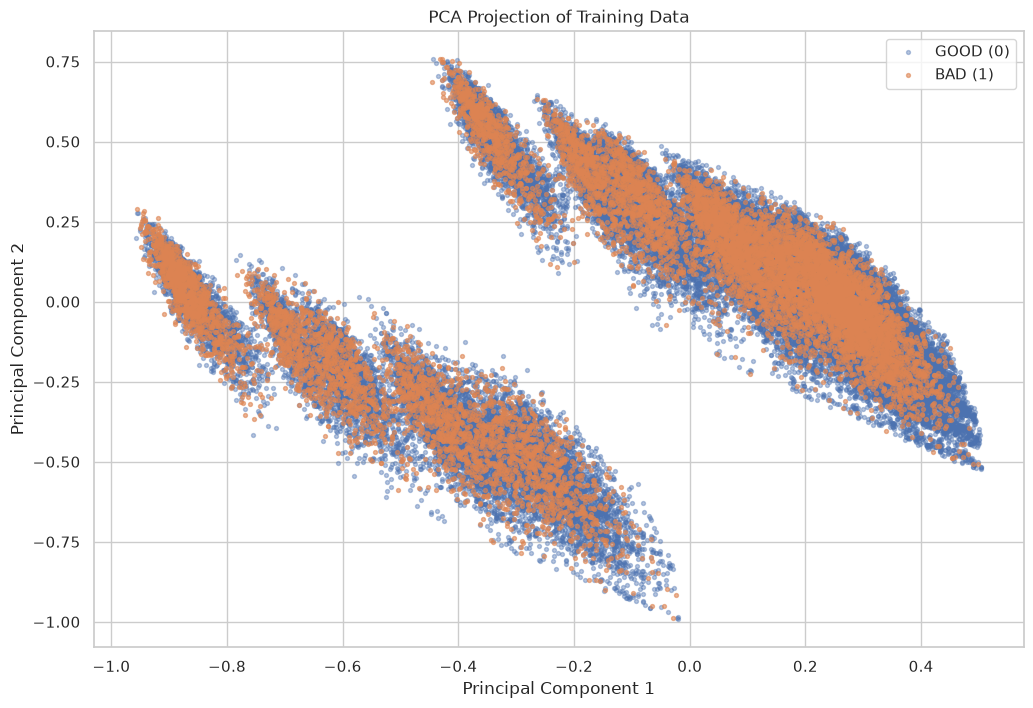

In [55]:
X_pca = pca.fit_transform(
    X_train_lr
)
plot_df = pd.DataFrame({
    'PC1': X_pca[:, 0],
    'PC2': X_pca[:, 1],
    'target': y_train.values
})

plt.figure(figsize=(12, 8))

good = plot_df['target'] == 0
bad = plot_df['target'] == 1

plt.scatter(
    plot_df.loc[good, 'PC1'],
    plot_df.loc[good, 'PC2'],
    s=8,
    alpha=0.4,
    label='GOOD (0)',
)

plt.scatter(
    plot_df.loc[bad, 'PC1'],
    plot_df.loc[bad, 'PC2'],
    s=8,
    alpha=0.6,
    label='BAD (1)',
)

plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.title('PCA Projection of Training Data')
plt.legend()
plt.grid(True)
plt.show()

In [56]:
# ── MLflow: log final model + artifacts, close run ──
mlflow.log_param("model_name", "LogisticRegression")
mlflow.sklearn.log_model(logreg, name="model")
mlflow.log_artifacts("reports/figures", artifact_path="figures")
mlflow.end_run()
print(f"MLflow run closed: {mlflow_run.info.run_id}")

MLflow run closed: 017d4888259a477cbf782a95c5010ea5
